<a href="https://colab.research.google.com/github/nikaivanisova/projekty/blob/main/USU_projekt_Ivani%C5%A1ov%C3%A1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Projekt USU**

Cieľom projektu je vyriešenie problému na vybranom datasete pomocou algoritmov strojového učenia, konkrétne riešenie klasifikačnej úlohy.

## ***Popis a príprava dát***

In [ ]:
import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/USU - projekt/mental_health_workplace_survey.csv', delimiter = ';')

Pre tento projekt sme vybrali dataset s názvom Mental Health & Burnout in the Workplace zo stránky Kaggle. (https://www.kaggle.com/datasets/khushikyad001/mental-health-and-burnout-in-the-workplace/data)

Dataset je umelo vytvorený, simuluje odpovede na prieskum, ktorého by sa zúčastnilo 3000 zamestnancov pracujúcich na rôznych pracovných pozíciách a žijúcich v rôznych krajinách.

Zaznamenané sú tieto atribúty:  
- **EmployeeID** - id zamestnanca,
- **Age** - vek,
- **Gender** - pohlavie,
- **Country** - krajina, kde pôsobí,
- **JobRole**   - pracovná pozícia,
- **Departmen**t - pracovné oddelenie,
- **YearsAtCompany** - počet rokov odpracovaných v súčasnej firme,
- **WorkHoursPerWeek** - počet hodín odpracovaných za týždeň,
- **RemoteWork** - práca z domu (yes, no, hybrid),
- **BurnoutLevel**- úroveň vyhorenia,
- **JobSatisfaction** - spokojnosť s prácou,
- **StressLevel**   - úroveň stresu,
- **ProductivityScore** - skóre produktivity,
- **SleepHours** - počet hodín spánku,
- **PhysicalActivityHrs**   - počet hodín strávených fyzickou aktivitou,
- **CommuteTime**   - čas strávený dochádzaním do práce,
- **HasMentalHealthSupport** - má podporu v oblasti duševného zdravia,
- **ManagerSupportScore** - skóre podpory manažéra,
- **HasTherapyAccess** - prístup k terapii,
- **MentalHealthDaysOff** - dni voľna kvôli duševnému zdraviu,
- **SalaryRange** - platové rozpätie,
- **WorkLifeBalanceScore** - skóre popisujúce balansovanie osobného a pracovného života,
- **TeamSize** - počet ľudí v tíme, v ktorom pracuje,
- **CareerGrowthScoreskóre** - skóre popisujúce možnosť kariérneho rastu,
- **BurnoutRisk** - riziko vyhorenia.



Cieľovým atribútom je BurnoutRisk, teda budeme predikovať riziko vyhorenia.

In [ ]:
df

,EmployeeID,Age,Gender,Country,JobRole,Department,YearsAtCompany,WorkHoursPerWeek,RemoteWork,BurnoutLevel,...,CommuteTime,HasMentalHealthSupport,ManagerSupportScore,HasTherapyAccess,MentalHealthDaysOff,SalaryRange,WorkLifeBalanceScore,TeamSize,CareerGrowthScore,BurnoutRisk
0,1001,50,Male,UK,Sales Associate,HR,14,47,No,3.37,...,117,No,3.15,Yes,8,40K-60K,8.82,6,9.20,0
1,1002,36,Male,Germany,Software Engineer,IT,1,59,Hybrid,7.39,...,8,Yes,4.40,Yes,4,80K-100K,2.80,45,8.46,1
2,1003,29,Non-binary,India,IT Admin,IT,13,59,Hybrid,7.10,...,75,No,3.63,No,6,80K-100K,7.28,7,7.96,1
3,1004,42,Male,Australia,HR Specialist,IT,15,31,Yes,4.18,...,43,Yes,4.50,Yes,9,60K-80K,1.31,11,8.90,0
4,1005,40,Male,Brazil,Customer Support,Support,6,34,Yes,8.28,...,58,Yes,5.51,Yes,6,<40K,1.17,18,8.88,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2995,3996,28,Female,Brazil,Marketing Manager,Sales,18,46,No,2.86,...,4,Yes,6.97,No,1,80K-100K,7.71,21,7.70,0
2996,3997,24,Male,Brazil,Customer Support,Marketing,14,31,No,2.43,...,1,Yes,5.58,Yes,0,60K-80K,3.76,2,2.59,0
2997,3998,22,Female,Canada,Marketing Manager,Marketing,0,38,No,6.87,...,25,No,3.81,No,0,40K-60K,3.30,2,6.95,0
2998,3999,57,Non-binary,Australia,Data Scientist,HR,2,41,No,3.62,...,24,No,9.72,No,3,100K+,6.20,37,9.60,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 25 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   EmployeeID              3000 non-null   int64  
 1   Age                     3000 non-null   int64  
 2   Gender                  3000 non-null   object 
 3   Country                 3000 non-null   object 
 4   JobRole                 3000 non-null   object 
 5   Department              3000 non-null   object 
 6   YearsAtCompany          3000 non-null   int64  
 7   WorkHoursPerWeek        3000 non-null   int64  
 8   RemoteWork              3000 non-null   object 
 9   BurnoutLevel            3000 non-null   float64
 10  JobSatisfaction         3000 non-null   float64
 11  StressLevel             3000 non-null   float64
 12  ProductivityScore       3000 non-null   float64
 13  SleepHours              3000 non-null   float64
 14  PhysicalActivityHrs     3000 non-null   

Výpis df.info() nám zobrazuje koľko máme hodnôt v každom atribúte a zároveň aké dátové typy atribúty nadobúdajú. Máme 17 numerických (konkrétne 9 desatinných a 8 celočíselných) a 8 kategoriálnych atribútov. V našom datasete máme celkovo 3000 záznamov. Pre každý atribút platí, že má 3000 nenullovych hodnôt, teda nemáme žiadne chýbajúce hodnoty.

Aby sme vedeli popísať všetky atribúty, potrebujeme ich rozdeliť na numerické a kategoriálne. Následne opíšeme najprv numerické, neskôr kategoriálne.

In [ ]:
targ_col = 'BurnoutRisk'
exp_cols = df.columns.to_list()
exp_cols.remove(targ_col)

X = df[exp_cols]
y = df[targ_col]

num_col = ['Age', 'YearsAtCompany', 'WorkHoursPerWeek', 'SleepHours', 'PhysicalActivityHrs', 'CommuteTime', 'ManagerSupportScore', 'WorkLifeBalanceScore', 'TeamSize', 'CareerGrowthScore','MentalHealthDaysOff', 'BurnoutLevel', 'JobSatisfaction', 'StressLevel', 'ProductivityScore']
cat_col = ['Gender', 'Country', 'JobRole', 'Department', 'RemoteWork', 'HasMentalHealthSupport', 'HasTherapyAccess', 'SalaryRange']
X_num = X[num_col]
X_cat = X[cat_col]

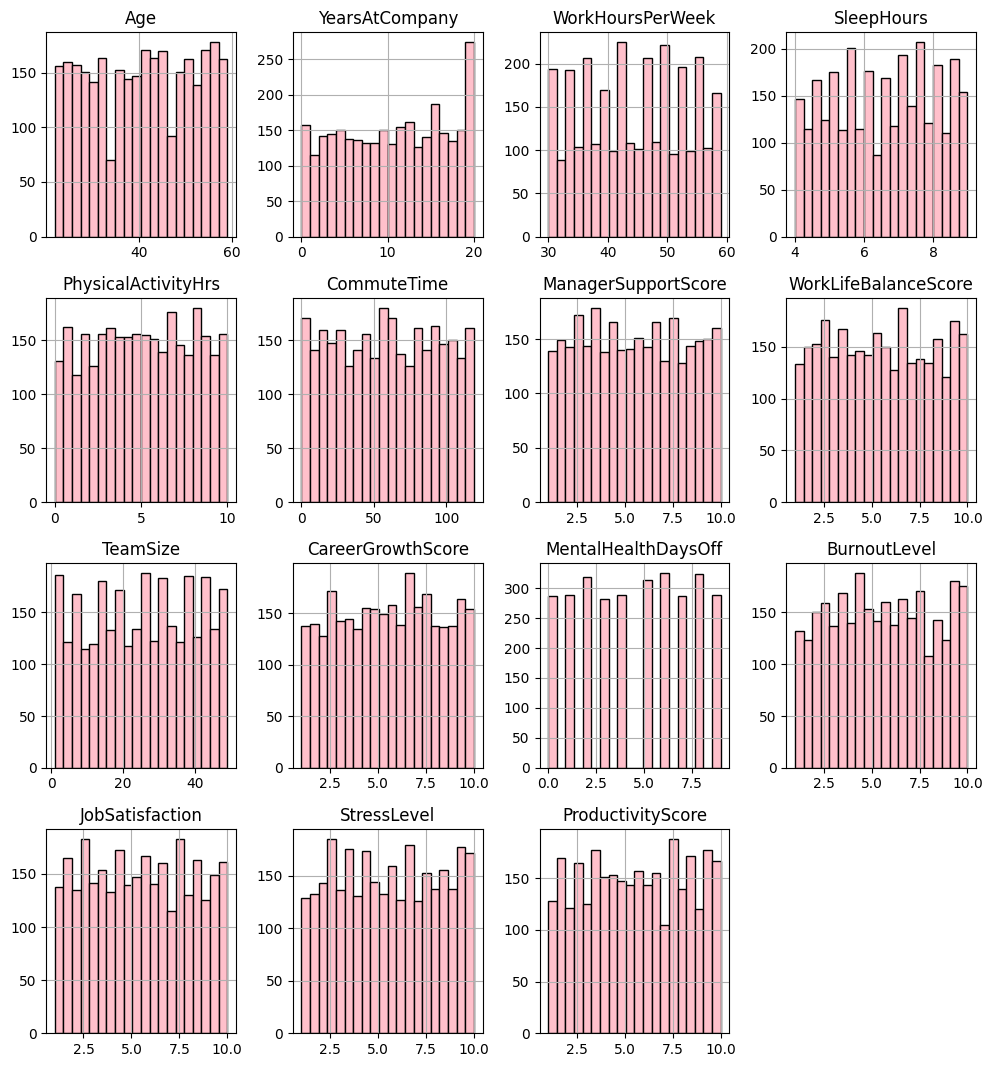

In [ ]:
import matplotlib.pyplot as plt

df[num_col].hist(bins=20, edgecolor='k', color='pink', figsize=(12,13))
plt.show()

In [ ]:
df.describe()

,EmployeeID,Age,YearsAtCompany,WorkHoursPerWeek,BurnoutLevel,JobSatisfaction,StressLevel,ProductivityScore,SleepHours,PhysicalActivityHrs,CommuteTime,ManagerSupportScore,MentalHealthDaysOff,WorkLifeBalanceScore,TeamSize,CareerGrowthScore,BurnoutRisk
count,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.00000,3000.000000,3000.000000
mean,2500.500000,40.805667,10.099333,44.504000,5.552487,5.471010,5.556210,5.561680,6.539000,5.030400,59.227000,5.479230,4.544667,5.492500,25.20100,5.555270,0.326667
std,866.169729,11.011705,6.035032,8.491526,2.576116,2.590369,2.598738,2.600466,1.441876,2.861026,34.809779,2.593181,2.854129,2.598903,14.08645,2.568464,0.469072
min,1001.000000,22.000000,0.000000,30.000000,1.000000,1.000000,1.000000,1.000000,4.000000,0.000000,0.000000,1.000000,0.000000,1.000000,1.00000,1.000000,0.000000
25%,1750.750000,31.000000,5.000000,37.000000,3.380000,3.210000,3.330000,3.387500,5.300000,2.600000,29.000000,3.250000,2.000000,3.237500,13.00000,3.330000,0.000000
50%,2500.500000,41.000000,10.000000,45.000000,5.520000,5.480000,5.540000,5.550000,6.600000,5.000000,59.000000,5.460000,5.000000,5.455000,25.00000,5.610000,0.000000
75%,3250.250000,50.000000,15.000000,52.000000,7.680000,7.700000,7.830000,7.810000,7.800000,7.500000,90.000000,7.710000,7.000000,7.742500,37.00000,7.680000,1.000000
max,4000.000000,59.000000,20.000000,59.000000,10.000000,10.000000,10.000000,10.000000,9.000000,10.000000,119.000000,9.990000,9.000000,10.000000,49.00000,9.990000,1.000000


Z výpisu príkazu df.descibe() vieme vyčítať základné charakteristiky numerických atribútov, ktorými sú počet hodnôt, priemer, štandardná odchýlka, minimum, 25% kvartil, 50% kvartil (medián), 75% kvartil a maximum. Môžeme vyčítať napr. vek respondentov sa pohybuje od 22 do 59, pričom polovica je mladšia ako 41, riziko vyhorenia má medián 0, čo znamená, že máme viac hodnôt pre hodnotu cieľového atribútu 0 ako 1 atď.

Na základe grafov vieme vyčítať, že v našich dátach ide o približne rovnomerné rozdelenie záznamov pre numerické atribúty, teda zaberajú pomerne širokú škálu hodnôt týchto atribútov, čo modelu strojového učenia umožňuje učiť sa na celých intervaloch, ktoré môžu dané atribúty pokrývať.

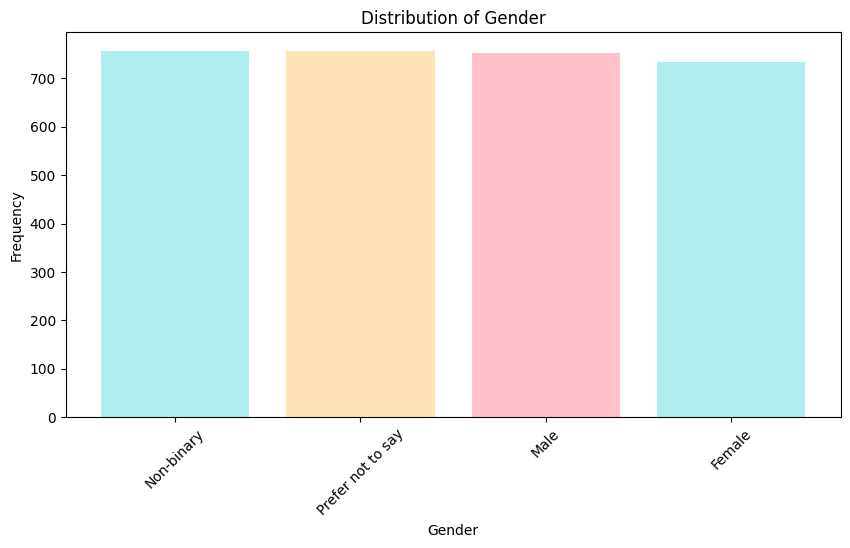

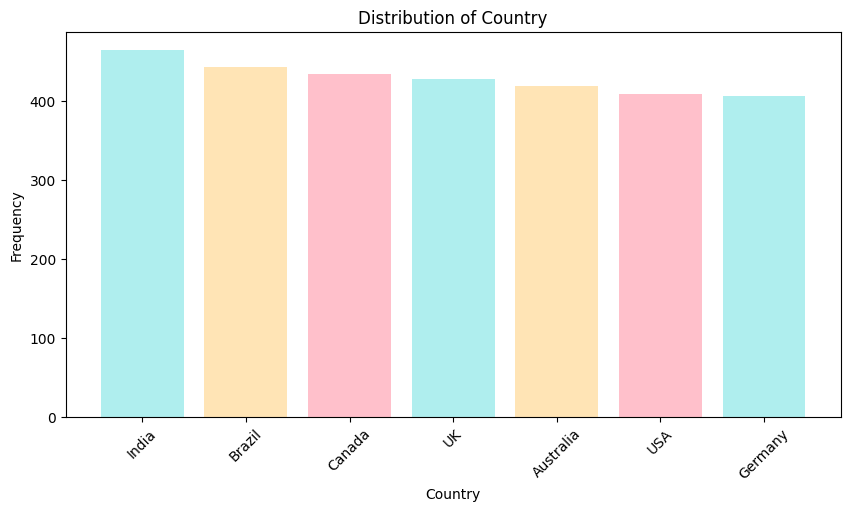

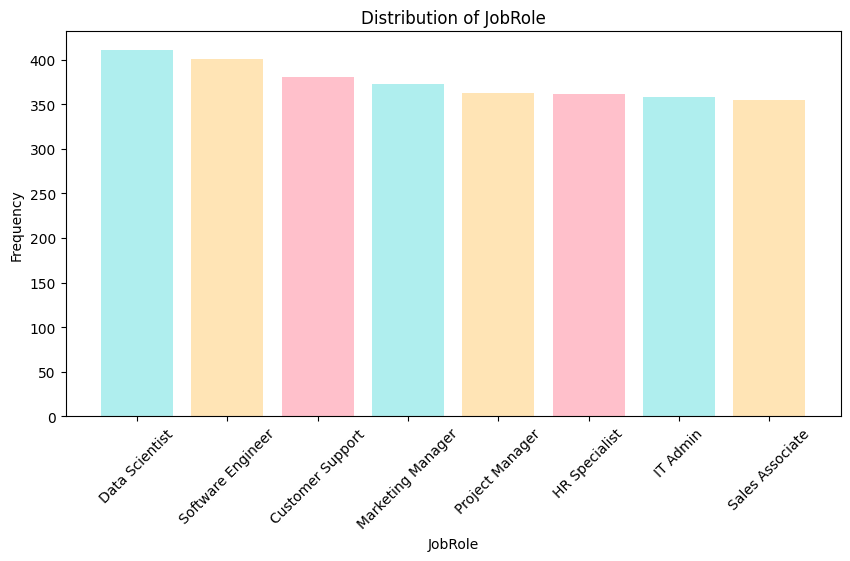

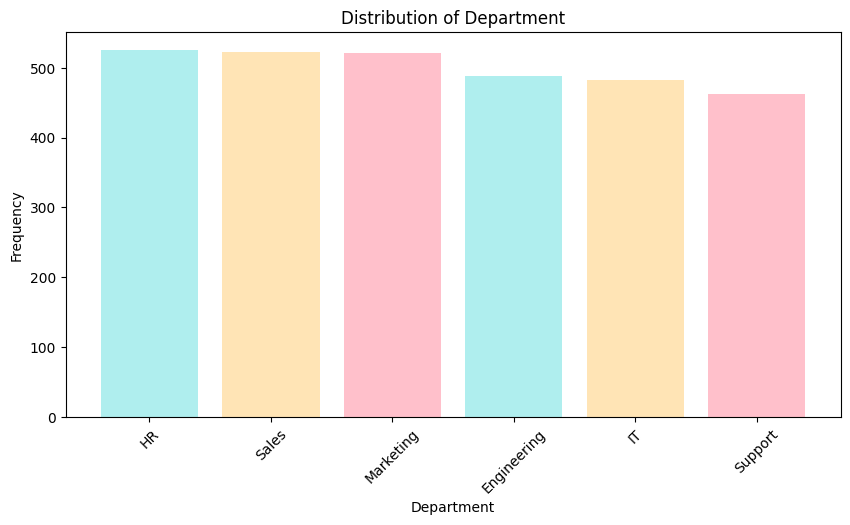

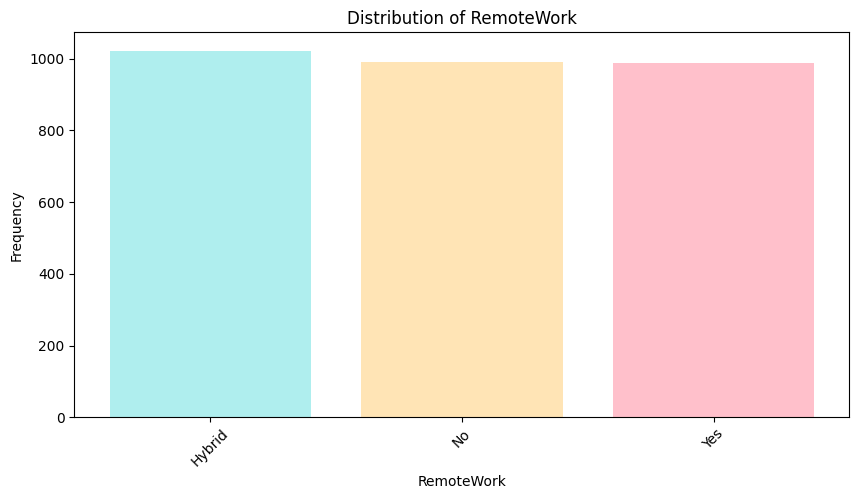

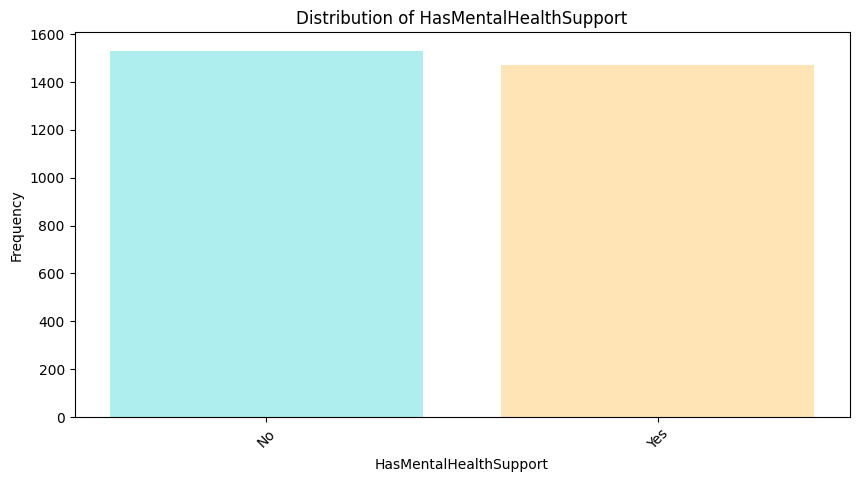

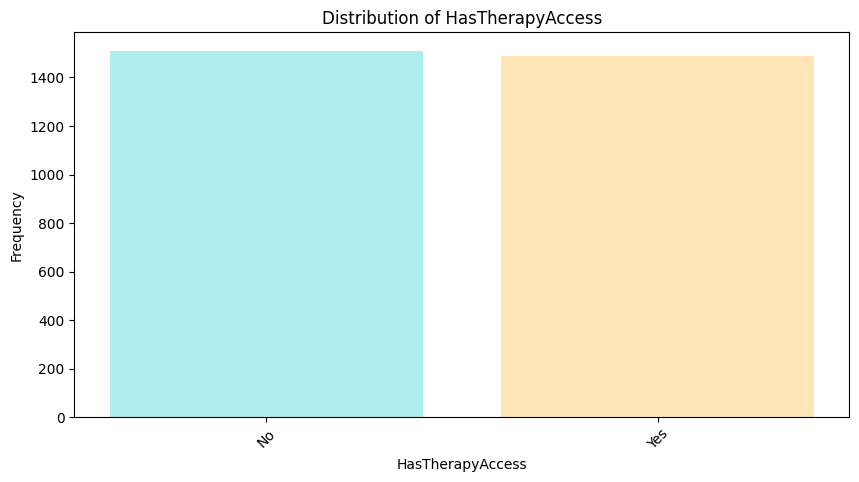

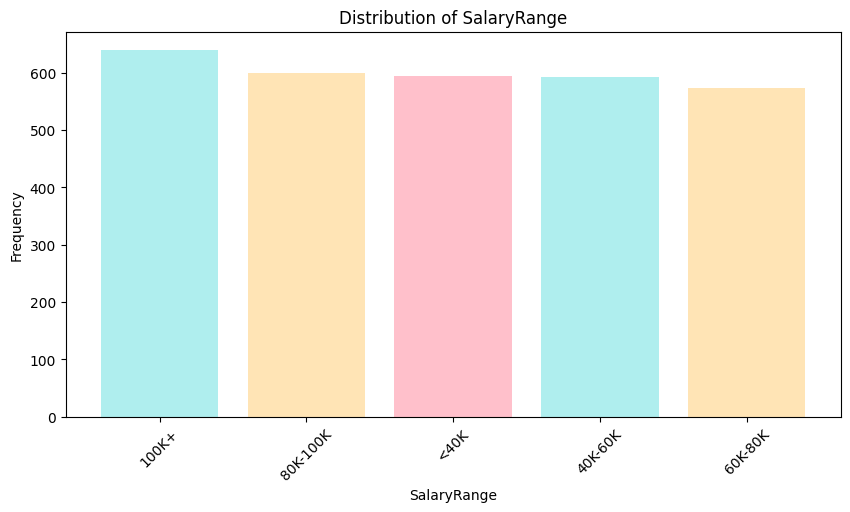

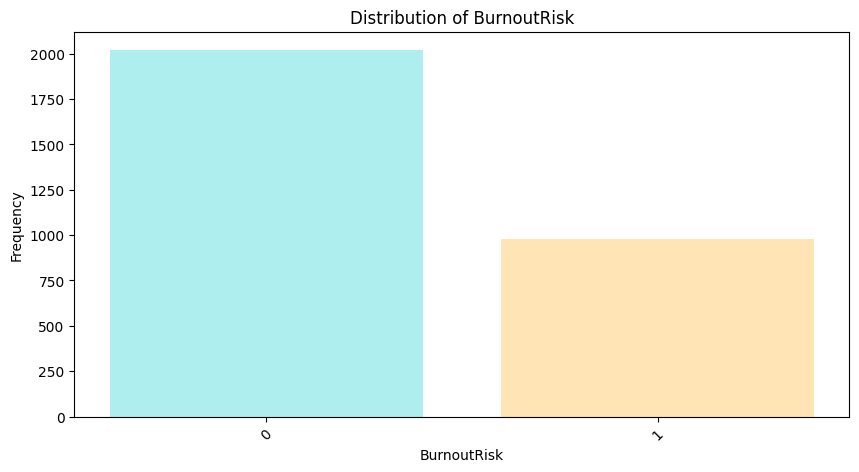

In [ ]:
import matplotlib.pyplot as plt

cat_col.append('BurnoutRisk')
for col in cat_col:
  fig, ax = plt.subplots(figsize=(10, 5))
  value_counts = df[col].value_counts()
  ax.bar(value_counts.index, value_counts.values, color=['paleturquoise', 'moccasin','pink'])
  ax.set_title('Distribution of '+col)
  ax.set_xlabel(col)
  ax.set_ylabel('Frequency')
  plt.xticks(value_counts.index.unique().tolist(), rotation=45)
  plt.show()


In [ ]:
for col in cat_col:
  display(df[col].value_counts())
cat_col.remove('BurnoutRisk')

,count
Gender,
Non-binary,757
Prefer not to say,757
Male,752
Female,734


,count
Country,
India,464
Brazil,443
Canada,434
UK,427
Australia,418
USA,408
Germany,406


,count
JobRole,
Data Scientist,411
Software Engineer,401
Customer Support,380
Marketing Manager,372
Project Manager,362
HR Specialist,361
IT Admin,358
Sales Associate,355


,count
Department,
HR,525
Sales,522
Marketing,521
Engineering,488
IT,482
Support,462


,count
RemoteWork,
Hybrid,1022
No,990
Yes,988


,count
HasMentalHealthSupport,
No,1531
Yes,1469


,count
HasTherapyAccess,
No,1511
Yes,1489


,count
SalaryRange,
100K+,640
80K-100K,600
<40K,594
40K-60K,593
60K-80K,573


,count
BurnoutRisk,
0,2020
1,980


Z prechádzajúcich výpisov príkazov vidíme, že vrámci kategórií konkrétneho atribútu nemáme príliš veľké odchýlky týkajúce sa zastúpenia hodnôt v daných kategóriách, čo je pre učenie modelu stromového učenia vhodné, pretože má dostatok príkladov z každej kategórie, a preto sa dokáže lepšie učiť a prinášať lepšie výsledky.

Pri cieľovom atribúte vidíme nevyváženosť, je k dispozícii okolo 2000 záznamov pre kategóriu 0 a okolo 1000 pre kategóriu 1. Kvôli nevyváženosti bude potrebné stratifikovať tréningovú a testovaciu množinu.

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(X_num)
X_num_stand = scaler.transform(X_num)
X_cat = pd.get_dummies(X_cat, dtype=int)

num_df = pd.DataFrame(X_num, columns=num_col)
num_df_stand = pd.DataFrame(X_num_stand, columns=num_col)
X_df = pd.concat([num_df, X_cat], axis=1)
X_df_stand = pd.concat([num_df_stand, X_cat], axis=1)

### Štandardizácia
Štandardizácia je proces normalizácie na nulový stred. Normalizácia je vhodná, pretože odstraňuje nevyváženosť atribútov (ak jeden atribút nadobúda vysoké hodnoty a druhý iba hodnoty 0 alebo 1, tak bez normalizácie má atribút s vyššími hodnotami väčší vplyv na model ako s nižšími). V našom datasete sú takýmito atribútmi napríklad počet ľudí v tíme a stres level. Vypočíta sa ako:
$$
\mathrm{z} = \frac{\mathrm{x}-\mathrm{u}}{\mathrm{s}}
$$
kde **x** je číslo, pre ktoré chceme vypočítať hodnotu po štandardizácii, **u** je priemer tréningových dát a **s** je smerodajná odchýlka tréningových dát.


### Zmena kategoriálnych atribútov
Modely strojového učenia, ktoré používame v tomto projekte, sa trénujú na číselných dátach. Preto potrebujeme premeniť kategoriálne dáta na numerické, čo sa dá spraviť pomocou príkazu pd.get_dummies. Funguje tak, že pre každú hodnotu každého kategoriálneho atribútu sa vytvorí jeden stĺpec, v ktorom budú hodnoty 0 a 1. Teda napríklad pri stĺpci RemoteWork, ktorý može mať Yes, No sa vytvoria dva stĺpce - RemoteWork_Yes, RemoteWork_No. Ak konkrétny záznam nadobúda v datasete pre RenoteWork hodnotu Yes, tak v stĺpci RemoteWork_Yes bude v tomto riadku 1 a v stĺpci RemoteWork_Nobude 0.

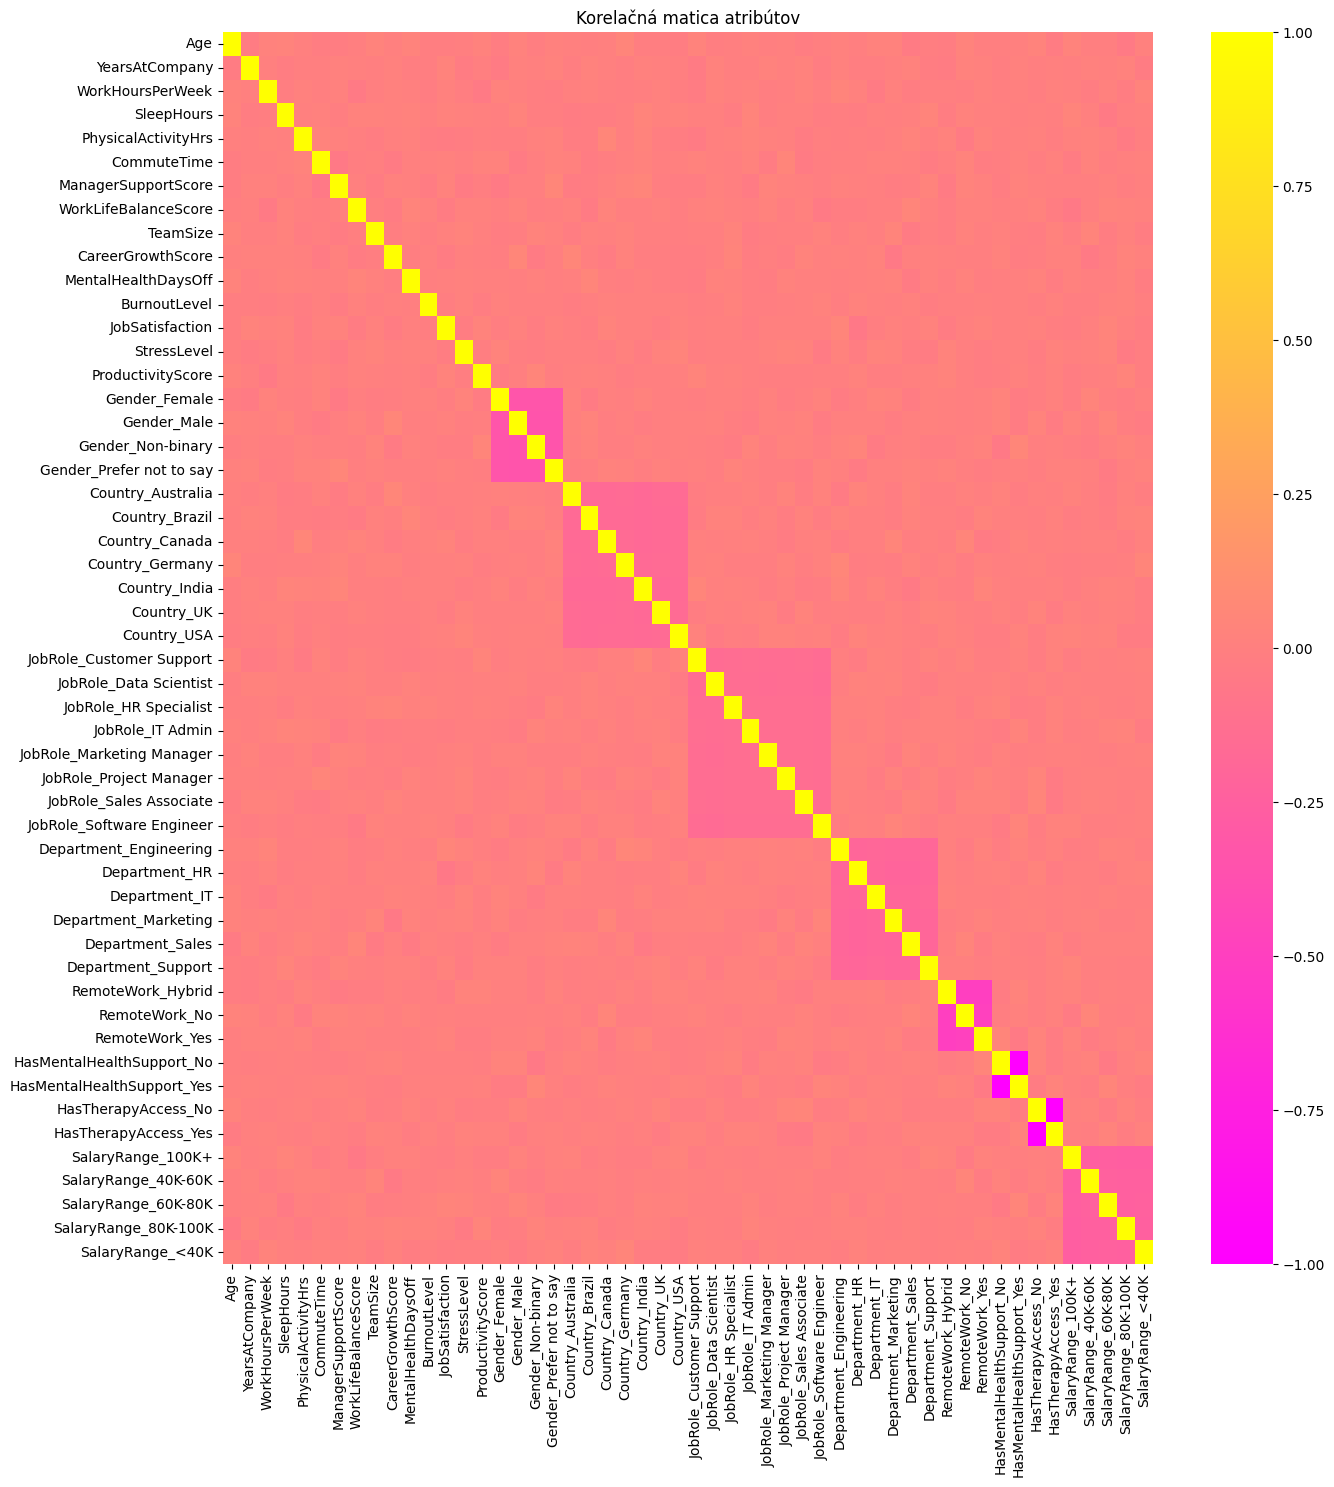

In [ ]:
corr_matrix = X_df.corr()
corr_matrix

import seaborn as sns

plt.figure(figsize=(15, 16))
sns.heatmap(corr_matrix, annot=False, cmap="spring", fmt=".2f")
plt.title('Korelačná matica atribútov')
plt.show()



Pri vyšetrovaní korelácie atribútov z datasetu si môžeme všimnúť, že medzi väčšinou atribútov je korelácia nízka. Zvýšená korelácie je prítomná po zmene kategoriálnych atribútov na numerické, čo je aj očakávané. Najvyššia korelácia je prítomná pri pôvodne kategoriálnych atribútoch, ktoré mohli nadobúdať iba odpoveď áno alebo nie, pretože ich záznamy sú presne opačné - tam kde bola odpoveď áno, nie je odpoveď nie a naopak. Ak by sa v datasete nachádzalo viac atribútov, ktoré majú vysokú koreláciu, bolo by vhodné ich odstrániť, pretože by sa znížilo trvanie trénovania modelov. V tomto prípade nebudem atribúty odstraňovať.

# **Výber modelov strojového učenia**

Pre tento projekt sme si zvolili rozhodovací strom a k najbližších susedov.

**Rozhodovací strom**

Rozhodovací strom je modelom strojového učenia používaný na riešenie klasifikačných úloh. Algoritmus je založený na rekurzívnom rozdeľovaní tréningovej množiny na 2 alebo viac častí na základe výberu jedného atribútu, ktorý výslednú klasifikáciu najviac rozlíši.Týmto spôsobom sa vytvára strom, v ktorom uzly reprezentujú atribúty, hrany hodnoty atribútov a listy klasifikované príklady.

To, ktorý atribút spôsobí najväčší rozdiel budeme zisťovať pomocou entropie.
Entropia popisuje mieru náhodnosti v dátach. Nadobúda hodnoty 0 až 1, pričom platí: čím je vyššia hodnota, tým je homogenita v skupine príkladov nižšia, čo znamená, že príklady v tejto skupine sú vzhľadom na cieľový atribút rôzne. Ak entropia nadobúda nízke hodnoty, vieme povedať, že atribút rozdeľuje dáta na skupiny, v ktorých sú príklady, vzhľadom na cieľový atribút, približne rovnaké.

Vzorec entropie pre uzol:
$$
H(A)
= \sum_{a \in A} p\bigl(x_i(A)=a\bigr)\cdot H\bigl(x_i(A)=a\bigr)
$$
kde
$$
H\bigl(x_i(A)=a\bigr)
= - \sum_{y_j \in \{1,\ldots,c\}} p(y_j)\,\log_2\bigl(p(y_j)\bigr)
$$
$
p(y_j)\
$
je pravdepodobnosť, že príklad patriaci hrane
$
x_i(A)=a
$
bude klasifikovaný do triedy
$
y_j
$ a
$
p\bigl(x_i(A)=a\bigr)
$ je pravdepodobnosť, že daný príklad bude patriť hrane
$
x_i(A)=a
$.




**K najbližších susedov**

Metóda k najbližších susedov je vhodná na použitie pri klasifikačných, ale aj regresných úlohách. Jej algoritmus spočíva v nájdení k najbližších susedov pomocou použitia niektorej z metrík (minkowského, euklidovská, manhattan). Ako cieľová hodnota sa priradí hodnota, ktorá sa u k najbližších susedoch vyskytuje najčastejšie. Nastavenie k je na nás. Pre malé k dochádza k rýchlemu výpočtu, ale viac reaguje na šum, zatiaľ čo vysoké hodnoty k môžu zahrňovať aj príklady z iných tried. Vo všeobecnosti sa odporúča zvoliť k z intervalu [1,10]< preto budeme v tomto projekte vyšetrovať aká hodnota k, z tohto intervalu, nám prinesie najlepšie výsledky.

V projekte použijeme Euklidovskú metriku, ktorá je najznámejšia a najviac používaná:
Vzorec Euklidovskej metriky:
$$\sqrt{\sum_{i=1}^{k} (x_i - y_i)^2}$$

# **Tréning a vyhodnotenie modelov**

## Technika rozdelenia na tréningovú a testovaciu množinu
Modely natrénujeme pomocou pomocou kFold krížovej validácie.

Kfold krížová validácia je spôsob vyhodnocovania modelov postavený na rozdelení dátovej sady na k množín (foldov), pričom sa vykonáva k iterácii, kde sa v každej z týchto iterácií na k-1 foldoch model trénuje a na 1 folde sa model testuje. V každej z týchto iterácií je testovacou množinou iný fold, teda platí, že na každom folde sa testuje práve raz. Tento typ tréningu je vhodný na použitie, ak máme k dispozícii menší počet údajov, teda nevieme s určitosťou povedať, že bude v tréningovej a testovacej množine dostatočné zastúpenie všetkých kategórií. Nastavenie k sa odporúča na 5 alebo 10. My nastavíme k na 10, pretože má presnejšie výsledky.

Ako bolo vyššie spomenuté, budeme používať stratifikáciu. Stratifikácia pri kfold krížovej validácii zabezpečí, že každý fold bude mať rovnaký pomer záznamov vzhľadom na cieľovú kategóriu ako celý dataset. V našom datasete máme 2020 záznamov pre kategóriu 0 a 980 pre kategóriu 1. Pomer kategórie 0 je preto 2020/3000, čo je približne 67%, zastúpenie kategórie 1 je 980/3000, čo je približne 33%. Keďže budeme rozdeľovať dataset na 10 foldov, každý fold bude obsahovať 300 záznamov. z týchto 300 záznamov podľa stratifikácie bude cca. 66% s kategóriou 0 a cca. 33%  s kategóriou 1. Teda každý fold bude obsahovať 202 záznamov s cieľovou hodnotou kategórie 0 a 98 s cieľovou hodnotou 1.

## Evaulačné kritériá
Pri klasifikačných úlohách strojového učenia môžeme použiť na vyhodnotenie presnosť, citlivosť, špecificitu, správnosť alebo f1-skóre. Modely v tomto projekte budeme vyhodnocovať na základe presnosti, citlivosti a f1-skóre. Všetky tieto kritériá nadobúdajú hodnoty z intervalu [0,1].

### Presnosť
$$\mathrm{Presnosť} = \frac{\mathrm{TP}}{\mathrm{TP}+\mathrm{FP}}$$


*   Presnosť hovorí o tom, koľko je zo všetkých pozitívne klasifikovaných, správne klasifikovaných ako pozitívnych.
*   Čím je presnosť vyššia, tým model klasifikuje menej falošných poplachov (false positives).
*   Ak by v našom prípade chceli firmy robiť preventívne opatrenia pre zamestnancov, u ktorých je riziko vyhorenia 1, je toto kritérium vhodné, pretože čím vyššiu bude mať hodnotu, tým menej bude prípadov, ktorým by bolo priradené riziko vyhorenia, aj keď u nich toto riziko nie je.
*   Falošne pozitívne klasifikácie by v našom prípade mohli znamenať vyššie výdavky, viac voľných dní alebo rôzne iné opatrenia, ktoré by mohli vo firme spôsobiť stratu, keby boli sprístupňované ľuďom, ktorí toto riziko nemajú.



### Citlivosť
$$\mathrm{Citlivosť} = \frac{\mathrm{TP}}{\mathrm{TP}+\mathrm{FN}}$$


*   Citlivosť prezrádza, koľko prípadov vie náš model klasifikovať ako pozitívnych zo všetkých skutočne pozitívnych prípadov.
*   Čím vyššia citlivosť, tým viac pozitívnych prípadov vie model správne identifikovať.
*   Citlivosť je vhodné kritérium, pretože čím vyššia je jej hodnota, tým viac zamestnancov s rizikom vyhorenia 1 vie model klasifikovať. Toto je vhodné, pretože by vedenia firiem vedeli predchádzať vyhoreniam zamestnancov pomocou preventívnych opatrení adresovaných rizikovým pracovníkom, čo by pomohlo nie len dotknutým pracovníkom, ale aj celkovo firme, pretože by neprichádzali o pracovnú silu, ak by už k vyhoreniu došlo. Taktiež by tieto opatrenia mohli mať vplyv na zlepšenie pracovnej morálky, produktivity.




### Presnosť vs. Citlivosť

*   Ak chceme dosiahnuť maximálnu hodnotu jedného z týchto kritérií, dochádza k tomu, že sa druhé kritérium znižuje.
*   Podľa predchádzajúceho popisu citlivosti a presnosti vieme zvážiť, že je vhodné, aby tieto kritériá boli vyvážené, čo znamená, že by bolo zabezpečené to, že sa identifikuje, čo najviac zamestnancov s rizikom vyhorenia 1 s ohľadom na to, že chceme, aby bolo čo najmenej falošne identifikovaných ako pozitívnych. Tento problém rieši F1-skóre, preto budeme toto kritérium používať aj na porovnanie výsledkov modelov strojového učenia.



### F1-skóre
$$\mathrm{F1-skóre} = \frac{\mathrm{Presnosť}*\mathrm{Citlivosť}}{\mathrm{Presnosť}+\mathrm{Citlivosť}}$$


*   F1-skóre je harmonickým priemerom presnosti a citlivosti.
*   Čím vyššiu hodnotu má, tým sú citlivosť a presnosť viac vyvážené.
*   Je náchylné na nízke hodnoty - ak jedna hodnota klesne, klesá celkové skóre.

## **Rozhodovací strom**

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import precision_score, recall_score, f1_score

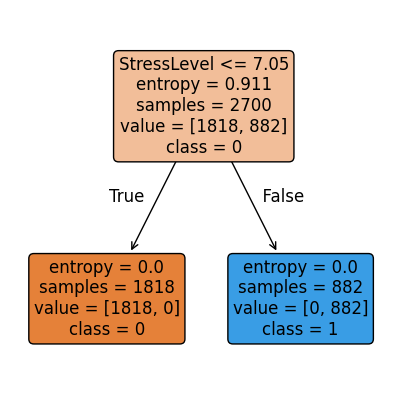

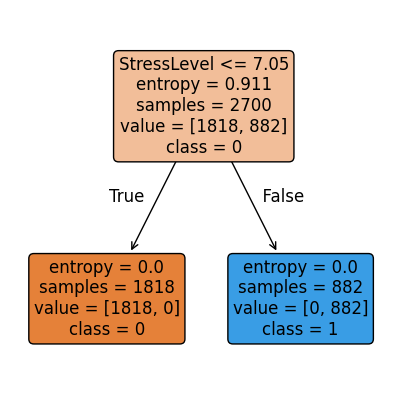

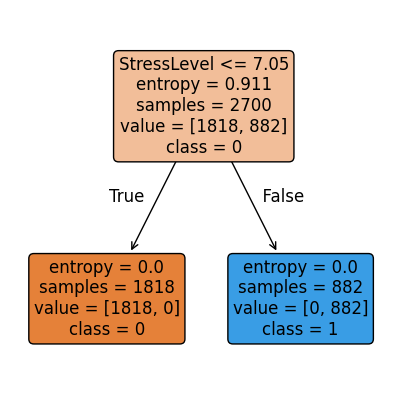

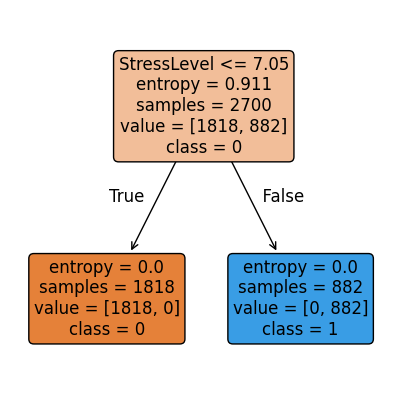

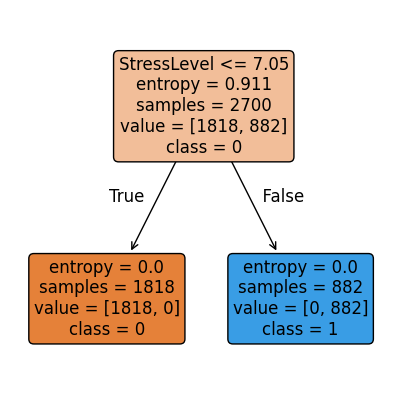

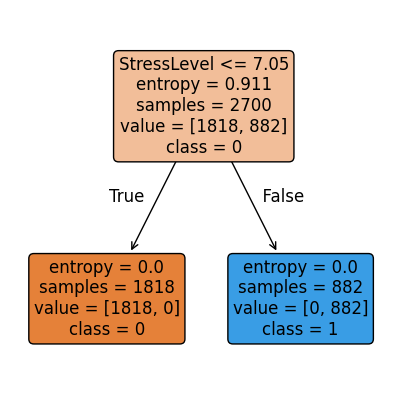

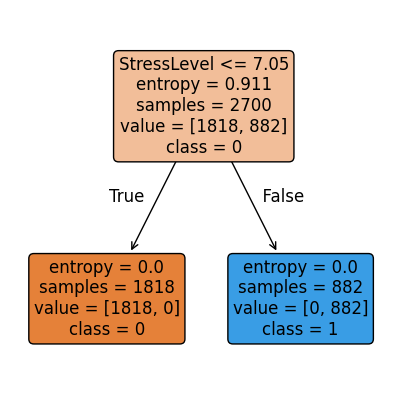

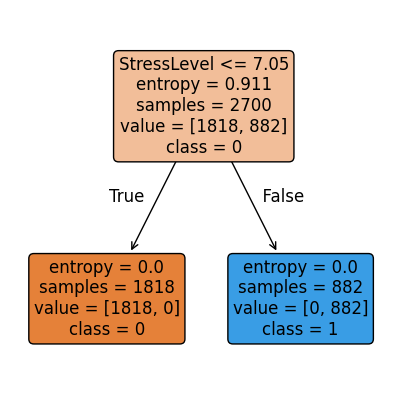

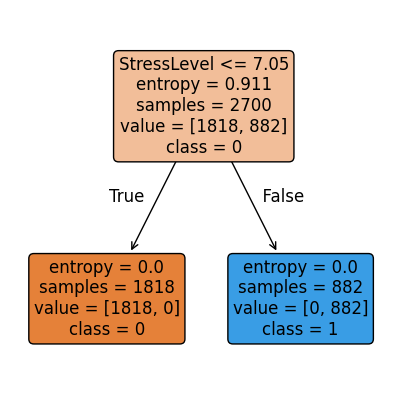

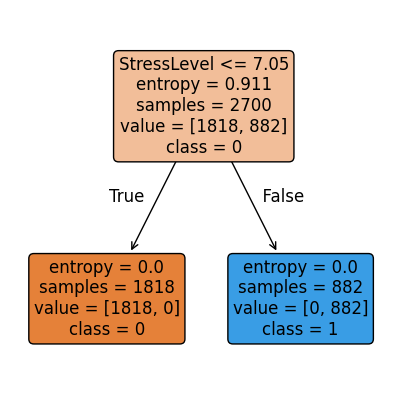

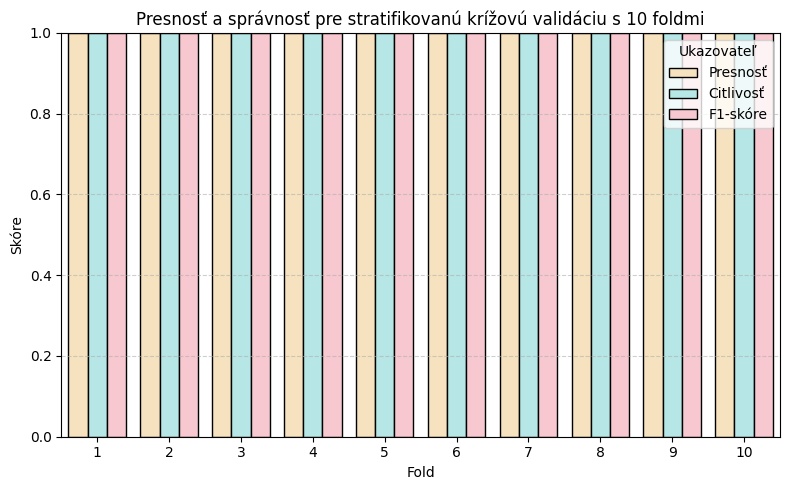

In [ ]:
import numpy as np
from sklearn import tree
from sklearn.model_selection import StratifiedKFold

model_dt = DecisionTreeClassifier(criterion='entropy')

skf = StratifiedKFold(n_splits=10, shuffle=True)

X = X_df.values

recall_scores_dt = []
precision_scores_dt = []
f1_scores_dt =[]

k = 10
folds = np.arange(1, k+1)

for train_index, test_index in skf.split(X,y):
  X_train, X_test = X[train_index], X[test_index]
  y_train, y_test = y[train_index], y[test_index]

  trained_model_dt = model_dt.fit(X_train, y_train)

  y_pred_dt = trained_model_dt.predict(X_test)

  recall = recall_score(y_test, y_pred_dt)
  precision = precision_score(y_test, y_pred_dt)
  f1 = f1_score(y_test, y_pred_dt)

  recall_scores_dt.append(recall)
  precision_scores_dt.append(precision)
  f1_scores_dt.append(f1)

  class_names = [str(cls) for cls in model_dt.classes_]

  plt.figure(figsize=(5, 5))
  tree.plot_tree(trained_model_dt,
               feature_names = exp_cols,
               class_names = class_names,
               filled = True,
               rounded = True,
               fontsize = 12)
  plt.show()

df_scores = pd.DataFrame({
    "Fold": np.tile(folds, 3),
    "Skóre": np.concatenate([precision_scores_dt, recall_scores_dt, f1_scores_dt]),
    "Ukazovateľ": ["Presnosť"] * k + ["Citlivosť"] * k + ["F1-skóre"] * k
})

plt.figure(figsize=(8, 5))
sns.barplot(data=df_scores, x='Fold', y='Skóre', hue='Ukazovateľ',
            palette=['moccasin', 'paleturquoise','pink'], edgecolor='black')

plt.ylim(0, 1)
plt.xlabel('Fold')
plt.ylabel('Skóre')
plt.title('Presnosť a správnosť pre stratifikovanú krížovú validáciu s 10 foldmi')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

Vyššie sú vykreslené stromy pre všetky foldy. Môžeme si všimnúť, že každý strom má rovnako rozdelené kategórie (1818,882), čo je výsledkom vyššie spomenutej stratifikácie foldov, a preto má aj každý strom rovnaký výsledok.


Každý strom má hĺbku 1. Model našiel atribút, ktorý rozdelí tréningovú množinu presne na dve časti, v ktorých sa nachádzajú hodnoty iba jednej kategórie, čo môžeme vidieť aj na hodnote entropie, ktorá je nulová. Hodnota entropie v koreni má hodnotu 0.91, čo zodpovedá rozdeleniu dát v tomto uzle.

## **Vyhodnotenie rozhodovacieho stromu**
Máme k dispozícii stĺpcové grafy znázorňujúce presnosť (precision), citlivosť (recall) a f1-skóre. Ako môžeme vidieť, všetky kritériá na všetkých foldoch dosahujú hodnotu 1.
Hodnota 1 pri citlivosti naznačuje, že model je schopný identifikovať >99% pozitívnych prípadov zo všetkých skutočne pozitívnych.
Hodnota 1 pri presnosti hovorí, že zo všetkých modelom pozitívne identifikovaných je skutočne pozitívnych >99%.
Hodnota 1 pre f1-skóre naznačuje, že presnosť a citlivosť sú vyvážené a nadobúdajú hodnotu 1.

Podľa týchto hodnôt vidíme, že model dosahuje veľmi malú, resp. nulovú chybu klasifikácie, teda je schopný nájsť všetky pozitívne prípady bez toho, aby niektoré boli nesprávne klasikované ako pozitívne, čo pre náš dataset znamená, že vie odhaliť všetkých zamestnancov ktorý majú riziko vyhorenia bez toho, aby niektorých, ktorí toto riziko v skutočnosti nemajú, identifikoval ako rizikových. Všetci zamestnanci s hodnotou cieľového atribútu BurnoutRisk 1, majú hodnotu atribútu StressLevel väčšiu ako 7.05, naopak zamestnanci s hodnotou cieľového atribútu 0 majú hodnotu StressLevel <=7.05.

Podľa tohto modelu vieme povedať, že ľudia, ktorí majú StressLevel > 7.05, majú riziko vyhorenia.

## **K najbližších susedov**

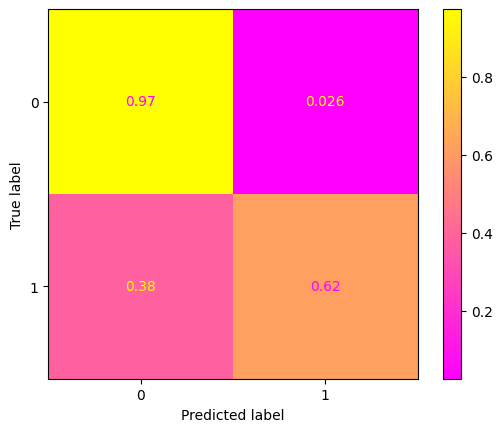

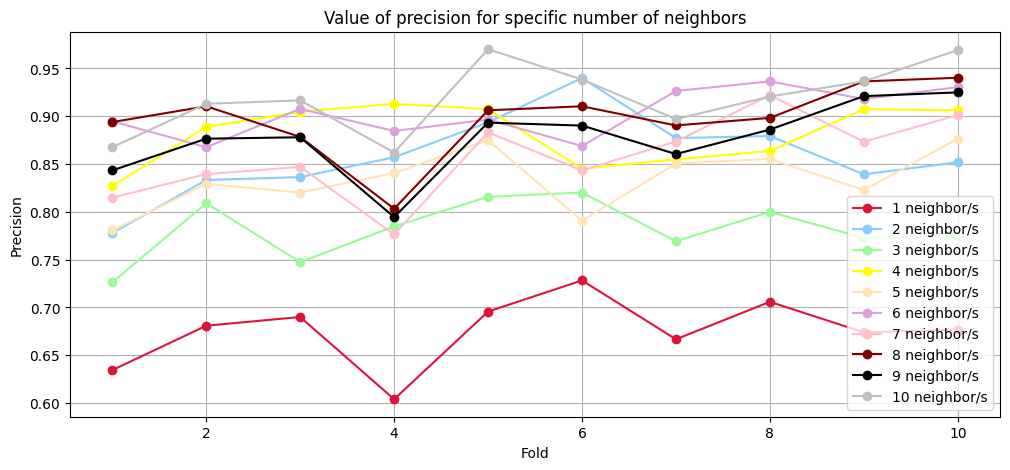

Priemerná presnosť pre jednotlivé počty susedov:
Počet susedov 1 0.675636284535197
Počet susedov 2 0.8585875519315493
Počet susedov 3 0.7819523571000803
Počet susedov 4 0.881822765949855
Počet susedov 5 0.8341582620619423
Počet susedov 6 0.903166264357484
Počet susedov 7 0.8574479407639153
Počet susedov 8 0.8968264470850918
Počet susedov 9 0.8768656965282922
Počet susedov 10 0.9191469411364228


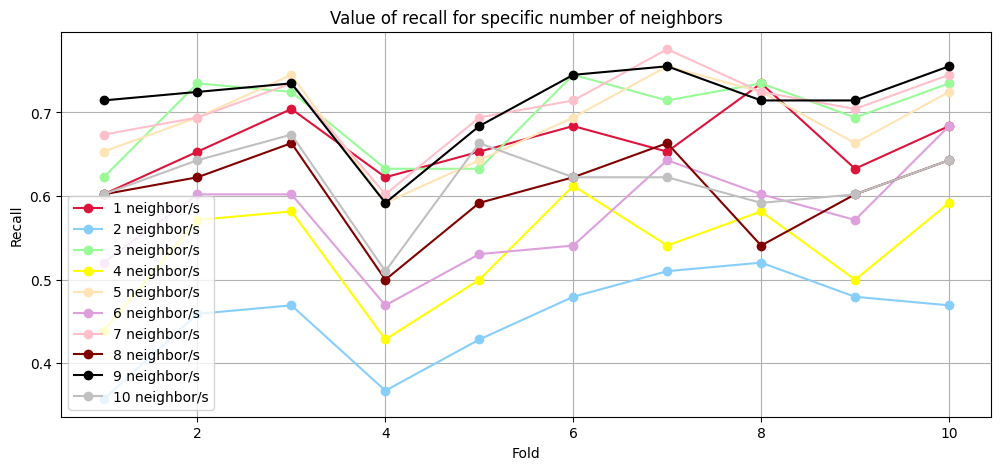

Priemerná citlivosť pre jednotlivé počty susedov:
Počet susedov 1 0.6622448979591836
Počet susedov 2 0.4540816326530613
Počet susedov 3 0.6969387755102041
Počet susedov 4 0.5346938775510204
Počet susedov 5 0.6887755102040817
Počet susedov 6 0.576530612244898
Počet susedov 7 0.7061224489795918
Počet susedov 8 0.6051020408163266
Počet susedov 9 0.713265306122449
Počet susedov 10 0.6173469387755103


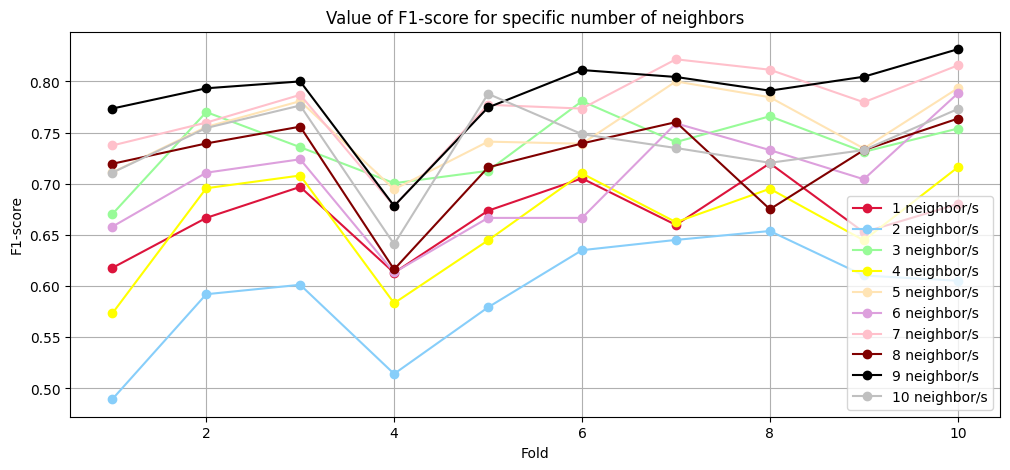

Priemerné f1-skóre pre jednotlivé počty susedov:
Počet susedov 1 0.6686078544876638
Počet susedov 2 0.5926314348912386
Počet susedov 3 0.736189943943508
Počet susedov 4 0.663359756448492
Počet susedov 5 0.7534622766544193
Počet susedov 6 0.7024094145735389
Počet susedov 7 0.7741230057578671
Počet susedov 8 0.7218464383464307
Počet susedov 9 0.7862183563938953
Počet susedov 10 0.7380537709340275


In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import cross_val_predict
X = X_df_stand.values

k = 10
folds = np.arange(1, k+1)
f1_scores_knn = []
recall_scores_knn = []
precision_scores_knn = []

number_of_neighbors = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

for i in number_of_neighbors:
  model_knn = KNeighborsClassifier(n_neighbors=i, metric = 'euclidean')
  skf = StratifiedKFold(n_splits=10, shuffle=True, random_state = 42)

  f1_scores_pom =[]
  recall_scores_pom = []
  precision_scores_pom = []

  for train_index, test_index in skf.split(X,y):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]
    trained_model_knn = model_knn.fit(X_train, y_train)
    y_pred = model_knn.predict(X_test)

    f1 = f1_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)

    f1_scores_pom.append(f1)
    recall_scores_pom.append(recall)
    precision_scores_pom.append(precision)
  f1_scores_knn.append(f1_scores_pom)
  recall_scores_knn.append(recall_scores_pom)
  precision_scores_knn.append(precision_scores_pom)

y_pred = cross_val_predict(model_knn, X, y, cv=skf)

cm = confusion_matrix(y, y_pred,normalize='true')

disp = ConfusionMatrixDisplay(confusion_matrix = cm)
disp.plot(cmap='spring')
plt.show()

fig1, ax1  = plt.subplots(figsize=(12, 5))
colors = ["crimson","lightskyblue","palegreen","yellow","moccasin","plum","pink","maroon","black","silver"]
for i in range(len(number_of_neighbors)):
  ax1.plot(folds, precision_scores_knn[i], marker = 'o',color=colors[i], label=str(number_of_neighbors[i])+' neighbor/s')

ax1.set_xlabel('Fold')
ax1.set_ylabel('Precision')
ax1.set_title('Value of precision for specific number of neighbors')
plt.legend()
plt.grid()
plt.show()

print('Priemerná presnosť pre jednotlivé počty susedov:')
for i in range (0,10):
  avg_precision_score = np.mean(precision_scores_knn[i])
  print('Počet susedov '+ str(number_of_neighbors[i]) +' '+ str(avg_precision_score))

fig2, ax2  = plt.subplots(figsize=(12, 5))
for i in range(len(number_of_neighbors)):
  ax2.plot(folds, recall_scores_knn[i], marker = 'o',color=colors[i], label=str(number_of_neighbors[i])+' neighbor/s')

ax2.set_xlabel('Fold')
ax2.set_ylabel('Recall')
ax2.set_title('Value of recall for specific number of neighbors')
plt.legend()
plt.grid()
plt.show()

print('Priemerná citlivosť pre jednotlivé počty susedov:')
for i in range (0,10):
  avg_recall_score = np.mean(recall_scores_knn[i])
  print('Počet susedov '+ str(number_of_neighbors[i]) +' '+ str(avg_recall_score))

fig3, ax3  = plt.subplots(figsize=(12, 5))
for i in range(len(number_of_neighbors)):
  ax3.plot(folds, f1_scores_knn[i], marker = 'o',color=colors[i], label=str(number_of_neighbors[i])+' neighbor/s')
ax3.set_xlabel('Fold')
ax3.set_ylabel('F1-score')
ax3.set_title('Value of F1-score for specific number of neighbors')
plt.legend()
plt.grid()
plt.show()

f1_scores_knn_2 = []
print('Priemerné f1-skóre pre jednotlivé počty susedov:')
for i in range (0,10):
  avg_f1_score = np.mean(f1_scores_knn[i])
  f1_scores_knn_2.append(avg_f1_score)
  print('Počet susedov '+ str(number_of_neighbors[i]) +' '+ str(avg_f1_score))

Model k najbližších susedov sme natrénovali na 10 foldoch a pre každý fold sme vypočítali presnosť, citlivosť a f1-skóre, čo je znázornené v grafoch. Nižšie je spočítaný priemer výsledkov všetkých foldov pre dané počty susedov.

### **Vyhodnotenie modelu knn**

Pomocou výpisu priemerov pre jednotlivé počty susedov môžeme vidieť, že presnosť nadobúda celkom vysoké hodnoty, čo ukazuje, že tento model klasifikuje nízky počet falošných poplachov. Na základe matice zámeny môžeme vidieť, že model zo všetkých skutočne negatívnych vie identifikovať v priemere 97% správne, mýli sa len v 2.6%, čo je veľmi dobrý výsledok, pretože sa v priemere len v 2.6% stáva, že dôjde k falošnému poplachu, teda model identifikuje riziko vyhorenia u zamestnancov, ktorí ho v skutočnosti nemajú.

Hodnoty citlivosti sú menšie ako hodnoty presnosti, čo naznačuje, že model o niečo horšie odhaľuje pozitívne prípady zo všetkých skutočne pozitívnych. Z matice zámeny vieme vyčítať, že priemerne 62% zo všetkých skutočne pozitívnych prípadov je aj identifikovaných ako pozitívne, ale v priemere v 38% skutočne pozitívnych prípadov dochádza ku chybe v klasifikácii - skutočne pozitívne prípady sú označené za negatívne, teda model identifikuje zamestnancov so skutočným rizikom vyhorenia ako zamestnancov bez rizika, čo môže viesť k tomu, že zamestnanci, ktorí potrebujú pomoc, ju nedostanú.

Najvyššiu hodnotu f1-skóre (0.786) dosahuje model pri klasifikácii pomocou 9 najbližších susedov. Pri tejto klasifikácii dochádza aj k najvyššej citlivosti (0.713). Presnosť pri tomto klasifikovaní nie je najvyššia možná, ale stále je pomerne vysoká (0.877). F1-skóre je vyššie, ak sú obe hodnoty čo najvyššie. Pri počtoch susedov, kde sú vyššie hodnoty presnosti je hodnota citlivosti nanajvýš 0.617, čo je dôvodom nižšieho f1-skóre.

Na porovnanie s modelom stromu vyberieme výsledky s najvyšším f1-skóre, teda klasifikáciu pomocou 9 najbližších susedov.

# **Porovnanie výsledkov algoritmov**

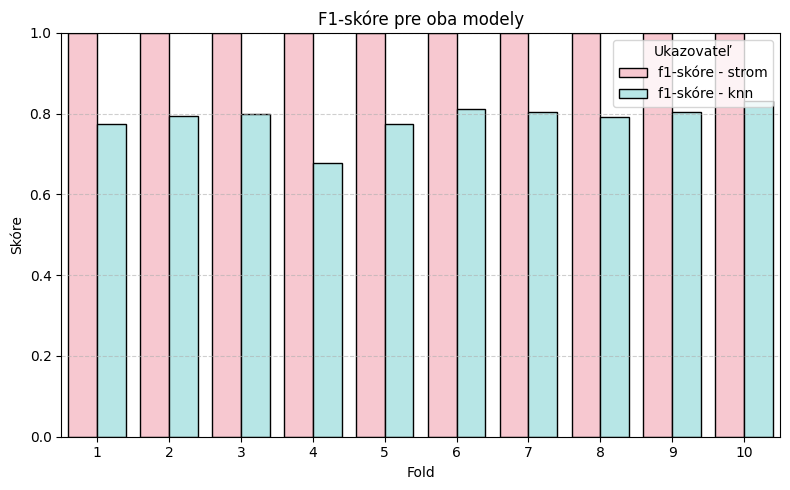

In [ ]:
f1_scores_knn_best = f1_scores_knn[8];

df_scores_porovnanie = pd.DataFrame({
    "Fold": np.tile(folds, 2),
    "Skóre": np.concatenate([f1_scores_dt, f1_scores_knn_best]),
    "Ukazovateľ": ["f1-skóre - strom"] * k + ["f1-skóre - knn"] * k
})

plt.figure(figsize=(8, 5))
sns.barplot(data=df_scores_porovnanie, x='Fold', y='Skóre', hue='Ukazovateľ',
            palette=['pink', 'paleturquoise'], edgecolor='black')

plt.ylim(0, 1)
plt.xlabel('Fold')
plt.ylabel('Skóre')
plt.title('F1-skóre pre oba modely')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

Ako vidíme, model rozhodovacieho stromu dosahuje na použitom datasete lepšie výsledky ako model k najbližších susedov, pretože na všetkých foldoch dosahuje f1-skóre 1, zatiaľ čo hodnota f1-skóre pre model k najbližších susedov kolíše medzi hodnotami 0.69 až 0.83.

Model rozhodovacieho stromu bol výkonnejší, pretože sa v dátach nachádza atribút, ktorý dáta rozdeľuje správne, s nulovou chybou po jednom delení. Model k najbližších susedov má horší výkon, pretože sa pozerá na všetky atribúty, a teda nie je schopný vyťažiť zo schopnosti jedného atribútu správne rozdeliť dáta.

Nami použitý dataset je umelo generovaný, teda nepochádza z reálnych dát. Pri umelo generovaných datasetoch je možné dosiahnuť hodnotu 1 pre f1-skóre, presnosť a citlivosť, pretože umelo generované dáta môžu byť generované tak, že sa v nich môže nachádzať 1 atribút, ktorý správne rozdelí dáta. Pri reálnych dátach by bol tento výsledok podozrivý, pretože reálne dáta obsahujú šumy a je veľmi zriedkavé, že sa dá nájsť práve 1 atribút, ktorý by rozdelil dáta správne, s nulovou chybou.

Teda v tomto prípade môžeme strom vybrať za model, ktorý je lepší na klasifikáciu tejto problematiky. S reálnymi dátami by bolo potrebné vyšetrovať príčiny tohto stavu.

### Porovnanie času
Trénovanie modelu rozhodovacieho stromu trvalo 0.087 s, zatiaľ čo trénovanie modelu k najbližších susedov trvalo 0.204 s, čo naznačuje, že modelu k najbližších susedov trvá trénovanie na rovnakých dátach dlhšie ako modelu rozhodovacích stromov.

### Možné vylepšenia
Keďže si náš model rozhodovacieho stromu našiel jeden konkrétny atribút, ktorý rozdelí správne dáta, tak by sme mohli využiť model random forest na to, aby sa na týchto dátach identifikovali aj iné možnosti klasifikácie, keďže v metóde random forest sa okrem iného náhodne vyberajú aj atribúty z celej množiny atribútov, ktoré sa budú používať na trénovanie stromu, z čoho vyplýva, že by sa niektoré stromy museli trénovať bez tohto atribútu. Pri trénovaní stromov v random forest by sme mohli určovať napr. maximálnu hĺbku stromov, minimálny počet dát v uzle a hľadať kedy je model najvýkonnejší.

Vylepšením metódy k najbližších susedov by mohlo byť vyhodnocovanie cieľového atribútu s váhou, čo znamená, že bližší susedia, by mali vyšší vplyv na výsledok ako tí, ktorí spadajú do k najbližších, ale sú vzdialenejšie. Mohli by sme vyskúšať zmeniť princíp normalizácie napr. do jednotkového intervalu, min-max normalizáciu a zistiť, či to bude mať vplyv na výkonnosť modelu.

# Záver
V tomto projekte sme sa zamerali na trénovanie modelov strojového učenia pre úlohu klasifikácie, konkrétne sme si vybrali model rozhodovacieho stromu a model k najbližších susedov. Postupne sme spravili tieto kroky: popísali dáta, pripravili ich pre jednotlivé modely, vybrali spôsob trénovania a vyhodnocovania modelov, natrénovali dané modely, vyhodnotili ich samostatne, porovnali výkonnosť modelov medzi sebou a navrhli možné vylepšenia.